In [1]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

# Path to one audio file
audio_path = r"C:\Users\LENOVO\OneDrive\Desktop\MusicGenre\archive\Data\genres_original\blues\blues.00006.wav"

# Load the audio
audio, sample_rate = librosa.load(audio_path, sr=None)

# Display basic information
print("Sample Rate:", sample_rate)
print("Number of Audio Samples:", len(audio))
print("Duration:", len(audio) / sample_rate, "seconds")

Sample Rate: 22050
Number of Audio Samples: 661794
Duration: 30.013333333333332 seconds


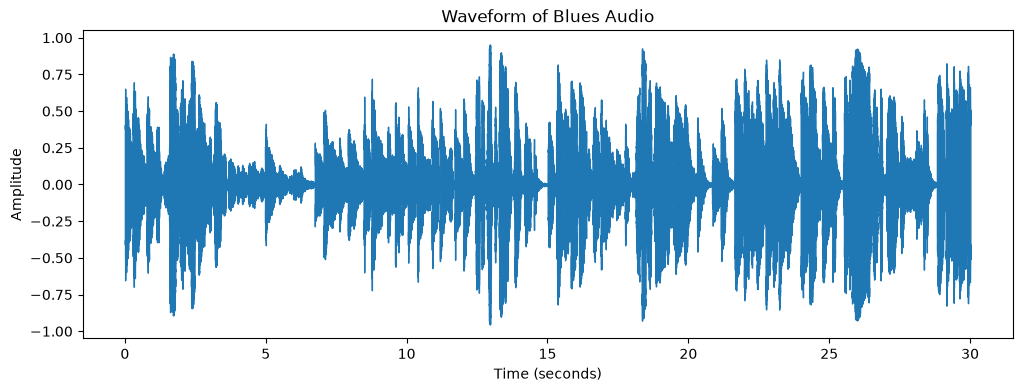

In [2]:
# Plot the waveform
plt.figure(figsize=(12, 4))
librosa.display.waveshow(audio, sr=sample_rate)

plt.title("Waveform of Blues Audio")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

In [3]:
# Extract MFCC features
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=13
)

print("MFCC shape:", mfcc.shape)

MFCC shape: (13, 1293)


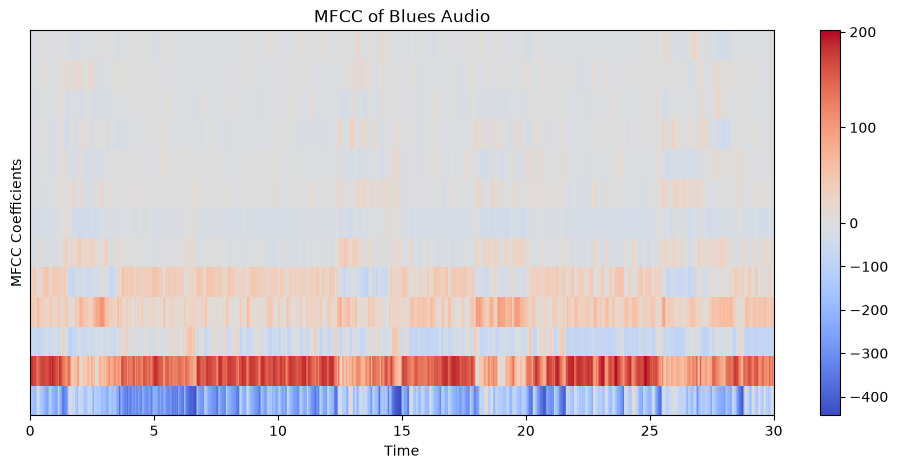

In [4]:
# Visualize MFCC features

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sample_rate
)

plt.colorbar()
plt.title("MFCC of Blues Audio")
plt.ylabel("MFCC Coefficients")
plt.show()

In [5]:
import os
import numpy as np
import pandas as pd

# Dataset location
data_path = r"C:\Users\LENOVO\OneDrive\Desktop\MusicGenre\archive\Data\genres_original"

# All 10 music genres
genres = [
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock"
]

features = []
failed_files = []

# Process every audio file
for genre in genres:
    genre_path = os.path.join(data_path, genre)

    print(f"Processing {genre}...")

    for filename in os.listdir(genre_path):

        if filename.lower().endswith(".wav"):

            file_path = os.path.join(genre_path, filename)

            try:
                audio, sr = librosa.load(file_path, sr=None)

                # MFCC features
                mfcc = librosa.feature.mfcc(
                    y=audio, sr=sr, n_mfcc=13
                )

                # Chroma features
                chroma = librosa.feature.chroma_stft(
                    y=audio, sr=sr
                )

                # Spectral features
                spectral_centroid = librosa.feature.spectral_centroid(
                    y=audio, sr=sr
                )

                spectral_bandwidth = librosa.feature.spectral_bandwidth(
                    y=audio, sr=sr
                )

                spectral_rolloff = librosa.feature.spectral_rolloff(
                    y=audio, sr=sr
                )

                zero_crossing_rate = librosa.feature.zero_crossing_rate(
                    audio
                )

                # Calculate mean and standard deviation
                feature_row = np.hstack([
                    np.mean(mfcc, axis=1),
                    np.std(mfcc, axis=1),
                    np.mean(chroma, axis=1),
                    np.std(chroma, axis=1),
                    np.mean(spectral_centroid),
                    np.std(spectral_centroid),
                    np.mean(spectral_bandwidth),
                    np.std(spectral_bandwidth),
                    np.mean(spectral_rolloff),
                    np.std(spectral_rolloff),
                    np.mean(zero_crossing_rate),
                    np.std(zero_crossing_rate)
                ])

                # Attach genre label
                feature_row = np.append(feature_row, genre)
                features.append(feature_row)

            except Exception as e:
                print(f"Skipped: {filename}")
                failed_files.append((genre, filename))

print("\nFeature extraction completed!")
print("Successful songs:", len(features))
print("Failed files:", len(failed_files))
print("Failed file details:", failed_files)

Processing blues...
Processing classical...
Processing country...
Processing disco...
Processing hiphop...
Processing jazz...
Skipped: jazz.00054.wav
Processing metal...
Processing pop...
Processing reggae...
Processing rock...

Feature extraction completed!
Successful songs: 999
Failed files: 1
Failed file details: [('jazz', 'jazz.00054.wav')]


In [6]:
# Create the feature DataFrame

mfcc_mean_names = [f"mfcc_mean_{i+1}" for i in range(13)]
mfcc_std_names = [f"mfcc_std_{i+1}" for i in range(13)]

chroma_mean_names = [f"chroma_mean_{i+1}" for i in range(12)]
chroma_std_names = [f"chroma_std_{i+1}" for i in range(12)]

other_feature_names = [
    "spectral_centroid_mean",
    "spectral_centroid_std",
    "spectral_bandwidth_mean",
    "spectral_bandwidth_std",
    "spectral_rolloff_mean",
    "spectral_rolloff_std",
    "zero_crossing_rate_mean",
    "zero_crossing_rate_std"
]

column_names = (
    mfcc_mean_names
    + mfcc_std_names
    + chroma_mean_names
    + chroma_std_names
    + other_feature_names
    + ["genre"]
)

df = pd.DataFrame(features, columns=column_names)

# Save our dataset permanently
df.to_csv("music_genre_features.csv", index=False)

print("Dataset shape:", df.shape)
print("Dataset saved successfully!")
display(df.head())

Dataset shape: (999, 59)
Dataset saved successfully!


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,...,chroma_std_12,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zero_crossing_rate_mean,zero_crossing_rate_std,genre
0,-113.59882354736328,121.57067108154297,-19.162261962890625,42.36394119262695,-6.3622660636901855,18.621931076049805,-13.69973373413086,15.339801788330078,-12.274304389953613,10.970945358276367,...,0.2926897704601288,1784.1226412753101,360.20200501843135,2002.4124072733878,292.9751020236874,3805.7230301080335,949.3434134740136,0.08304482066898686,0.027693783681433826,blues
1,-207.52383422851562,123.98513793945312,8.94701862335205,35.867149353027344,2.909594774246216,21.519472122192383,-8.556513786315918,23.370676040649414,-10.103608131408691,11.899242401123047,...,0.26917386054992676,1530.2617669893777,613.1194898044935,2038.9876082704006,462.49876020502285,3550.7136156830047,1725.7783473036059,0.05603980870552978,0.03804630719740175,blues
2,-90.75716400146484,140.4408721923828,-29.08454704284668,31.68669319152832,-13.976547241210938,25.753751754760742,-13.664990425109863,11.634442329406738,-11.778322219848633,9.71475601196289,...,0.35300037264823914,1552.8324814348227,395.56416787159105,1747.7540868495232,276.21624390702664,3042.4101154654873,885.5116455461281,0.07629120746326373,0.031730570099435376,blues
3,-199.57513427734375,150.0861053466797,5.6634039878845215,26.85527801513672,1.770071268081665,14.232646942138672,-4.827844619750977,9.286852836608887,-0.7561201453208923,8.134434700012207,...,0.3372573256492615,1070.1534175250665,429.378631790483,1596.4225644535768,408.1076380606343,2184.8790286035382,1221.9156472279285,0.03330886262567672,0.020561103742135052,blues
4,-160.3541717529297,126.20948028564453,-35.58139419555664,22.139257431030273,-32.473548889160156,10.850702285766602,-23.35007095336914,0.49324920773506165,-11.796538352966309,1.2035191059112549,...,0.21841824054718018,1835.12851277257,585.874983035052,1748.410758453808,297.2855604932637,3579.9574708164155,1253.928346818156,0.10146053871809745,0.04420548271538123,blues


In [7]:
# Check the number of songs in each genre

print(df["genre"].value_counts())

# Check for missing values
print("\nMissing values:", df.isnull().sum().sum())

genre
blues        100
classical    100
country      100
disco        100
hiphop       100
metal        100
pop          100
reggae       100
rock         100
jazz          99
Name: count, dtype: int64

Missing values: 0


In [8]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("genre", axis=1)
y = df["genre"]

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Save the split datasets as backup
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Training and testing datasets saved!")

Training samples: 799
Testing samples: 200
Training and testing datasets saved!


In [9]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

# Save the scaler for future use
import joblib

joblib.dump(scaler, "scaler.pkl")

print("Scaler saved successfully!")

Scaled training data shape: (799, 58)
Scaled testing data shape: (200, 58)
Scaler saved successfully!


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

# Predict genres for test songs
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.615

Classification Report:
              precision    recall  f1-score   support

       blues       0.47      0.40      0.43        20
   classical       0.95      0.95      0.95        20
     country       0.52      0.60      0.56        20
       disco       0.38      0.50      0.43        20
      hiphop       0.50      0.60      0.55        20
        jazz       0.78      0.90      0.84        20
       metal       0.82      0.70      0.76        20
         pop       0.64      0.70      0.67        20
      reggae       0.64      0.45      0.53        20
        rock       0.50      0.35      0.41        20

    accuracy                           0.61       200
   macro avg       0.62      0.61      0.61       200
weighted avg       0.62      0.61      0.61       200



In [11]:
import joblib

# Save Random Forest model
joblib.dump(rf_model, "random_forest.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [12]:
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Predict genres
y_pred_svm = svm_model.predict(X_test_scaled)

# Evaluate
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

# Save the model
joblib.dump(svm_model, "svm_model.pkl")

print("\nSVM model saved successfully!")

SVM Accuracy: 0.665

Classification Report:
              precision    recall  f1-score   support

       blues       0.61      0.70      0.65        20
   classical       0.90      0.90      0.90        20
     country       0.57      0.60      0.59        20
       disco       0.47      0.40      0.43        20
      hiphop       0.48      0.65      0.55        20
        jazz       0.82      0.90      0.86        20
       metal       0.83      0.75      0.79        20
         pop       0.70      0.80      0.74        20
      reggae       0.62      0.50      0.56        20
        rock       0.69      0.45      0.55        20

    accuracy                           0.67       200
   macro avg       0.67      0.67      0.66       200
weighted avg       0.67      0.67      0.66       200


SVM model saved successfully!


In [13]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train
knn_model.fit(X_train_scaled, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test_scaled)

# Evaluate
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))

# Save model
joblib.dump(knn_model, "knn_model.pkl")

print("\nKNN model saved successfully!")

KNN Accuracy: 0.62

Classification Report:
              precision    recall  f1-score   support

       blues       0.75      0.60      0.67        20
   classical       0.95      0.90      0.92        20
     country       0.52      0.65      0.58        20
       disco       0.41      0.45      0.43        20
      hiphop       0.38      0.50      0.43        20
        jazz       0.84      0.80      0.82        20
       metal       0.74      0.70      0.72        20
         pop       0.55      0.80      0.65        20
      reggae       0.57      0.40      0.47        20
        rock       0.73      0.40      0.52        20

    accuracy                           0.62       200
   macro avg       0.64      0.62      0.62       200
weighted avg       0.64      0.62      0.62       200


KNN model saved successfully!


In [14]:
from sklearn.model_selection import GridSearchCV

# Parameters to test
param_grid = {
    'C': [1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}

# Create SVM
svm = SVC(kernel='rbf')

# Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    svm,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train and find the best combination
grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

# Save the grid search results
joblib.dump(grid_search, "grid_search_svm.pkl")

Best Parameters: {'C': 10, 'gamma': 'scale'}
Best Cross-Validation Accuracy: 0.7196147798742139


['grid_search_svm.pkl']

In [17]:
# Get the best model
best_svm = grid_search.best_estimator_

# Predict on test data
y_pred_tuned = best_svm.predict(X_test_scaled)

# Calculate test accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned SVM Test Accuracy:", tuned_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

# Save final model
joblib.dump(best_svm, "best_svm.pkl")

print("\nFinal Tuned SVM saved successfully!")

Tuned SVM Test Accuracy: 0.695

Classification Report:
              precision    recall  f1-score   support

       blues       0.75      0.75      0.75        20
   classical       0.90      0.95      0.93        20
     country       0.52      0.70      0.60        20
       disco       0.56      0.50      0.53        20
      hiphop       0.63      0.60      0.62        20
        jazz       0.82      0.90      0.86        20
       metal       0.94      0.80      0.86        20
         pop       0.64      0.80      0.71        20
      reggae       0.67      0.60      0.63        20
        rock       0.54      0.35      0.42        20

    accuracy                           0.69       200
   macro avg       0.70      0.69      0.69       200
weighted avg       0.70      0.69      0.69       200


Final Tuned SVM saved successfully!


In [19]:
#trying to increase ouyr model's accuracy by experimenting around
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Expanded parameter combinations
param_grid_advanced = {
    'C': [0.1, 1, 3, 10, 30, 100, 300],
    'gamma': ['scale', 0.001, 0.003, 0.01, 0.03, 0.1]
}

# Create SVM
advanced_svm = SVC(kernel='rbf')

# Perform 5-fold cross-validation
advanced_grid = GridSearchCV(
    advanced_svm,
    param_grid_advanced,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Train and search
advanced_grid.fit(X_train_scaled, y_train)

print("Best Parameters:", advanced_grid.best_params_)
print("Best CV Accuracy:", advanced_grid.best_score_)

# Save search results
joblib.dump(advanced_grid, "advanced_svm_search.pkl")

Best Parameters: {'C': 3, 'gamma': 0.01}
Best CV Accuracy: 0.7221305031446541


['advanced_svm_search.pkl']

In [20]:
# Get the best model from advanced tuning
advanced_best_svm = advanced_grid.best_estimator_

# Predict on test data
y_pred_advanced = advanced_best_svm.predict(X_test_scaled)

# Calculate test accuracy
advanced_accuracy = accuracy_score(
    y_test,
    y_pred_advanced
)

print("Advanced SVM Test Accuracy:", advanced_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_advanced))

# Save the advanced model
joblib.dump(advanced_best_svm, "advanced_best_svm.pkl")

print("\nAdvanced SVM saved successfully!")

Advanced SVM Test Accuracy: 0.67

Classification Report:
              precision    recall  f1-score   support

       blues       0.64      0.70      0.67        20
   classical       1.00      0.90      0.95        20
     country       0.54      0.65      0.59        20
       disco       0.42      0.40      0.41        20
      hiphop       0.48      0.60      0.53        20
        jazz       0.86      0.95      0.90        20
       metal       0.88      0.75      0.81        20
         pop       0.71      0.75      0.73        20
      reggae       0.61      0.55      0.58        20
        rock       0.64      0.45      0.53        20

    accuracy                           0.67       200
   macro avg       0.68      0.67      0.67       200
weighted avg       0.68      0.67      0.67       200


Advanced SVM saved successfully!


In [21]:
from sklearn.ensemble import ExtraTreesClassifier

# Create Extra Trees model
extra_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=42,
    max_features="sqrt"
)

# Train
extra_model.fit(X_train_scaled, y_train)

# Predict
y_pred_extra = extra_model.predict(X_test_scaled)

# Evaluate
extra_accuracy = accuracy_score(y_test, y_pred_extra)

print("Extra Trees Accuracy:", extra_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_extra))

# Save model
joblib.dump(extra_model, "extra_trees.pkl")

print("\nExtra Trees model saved successfully!")

Extra Trees Accuracy: 0.645

Classification Report:
              precision    recall  f1-score   support

       blues       0.67      0.50      0.57        20
   classical       0.94      0.85      0.89        20
     country       0.54      0.70      0.61        20
       disco       0.40      0.40      0.40        20
      hiphop       0.50      0.65      0.57        20
        jazz       0.68      0.85      0.76        20
       metal       0.78      0.90      0.84        20
         pop       0.68      0.75      0.71        20
      reggae       0.73      0.55      0.63        20
        rock       0.60      0.30      0.40        20

    accuracy                           0.65       200
   macro avg       0.65      0.64      0.64       200
weighted avg       0.65      0.65      0.64       200


Extra Trees model saved successfully!


In [24]:

import os
import numpy as np
import pandas as pd
import librosa

# Dataset location
data_path = r"C:\Users\LENOVO\OneDrive\Desktop\MusicGenre\archive\Data\genres_original"

genres = [
    "blues", "classical", "country", "disco", "hiphop",
    "jazz", "metal", "pop", "reggae", "rock"
]

features_v2 = []
failed_files_v2 = []

print("Starting advanced feature extraction...")

for genre in genres:
    genre_path = os.path.join(data_path, genre)

    print(f"\nProcessing {genre}...")

    for filename in os.listdir(genre_path):

        if filename.lower().endswith(".wav"):
            file_path = os.path.join(genre_path, filename)

            try:
                audio, sr = librosa.load(file_path, sr=None)

                # 1. MFCC features
                mfcc = librosa.feature.mfcc(
                    y=audio, sr=sr, n_mfcc=13
                )

                # 2. Chroma features
                chroma = librosa.feature.chroma_stft(
                    y=audio, sr=sr
                )

                # 3. Spectral features
                centroid = librosa.feature.spectral_centroid(
                    y=audio, sr=sr
                )

                bandwidth = librosa.feature.spectral_bandwidth(
                    y=audio, sr=sr
                )

                rolloff = librosa.feature.spectral_rolloff(
                    y=audio, sr=sr
                )

                zcr = librosa.feature.zero_crossing_rate(
                    y=audio
                )

                # 4. NEW: Spectral Contrast
                contrast = librosa.feature.spectral_contrast(
                    y=audio, sr=sr
                )

                # 5. NEW: RMS Energy
                rms = librosa.feature.rms(y=audio)

             # 6. NEW: Tempo
                tempo, _ = librosa.beat.beat_track(
                    y=audio, sr=sr
                )

                # 7. NEW: Tonnetz
                harmonic = librosa.effects.harmonic(audio)

                tonnetz = librosa.feature.tonnetz(
                    y=harmonic, sr=sr
                )

                # Combine all features
                feature_row = np.hstack([
                    np.mean(mfcc, axis=1),
                    np.std(mfcc, axis=1),

                    np.mean(chroma, axis=1),
                    np.std(chroma, axis=1),

                    np.mean(centroid),
                    np.std(centroid),

                    np.mean(bandwidth),
                    np.std(bandwidth),

                    np.mean(rolloff),
                    np.std(rolloff),

                    np.mean(zcr),
                    np.std(zcr),

                    # New features
                    np.mean(contrast, axis=1),
                    np.std(contrast, axis=1),

                    np.mean(rms),
                    np.std(rms),

                    float(np.mean(tempo)),

                    np.mean(tonnetz, axis=1),
                    np.std(tonnetz, axis=1)
                ])

                feature_row = np.append(feature_row, genre)
                features_v2.append(feature_row)

            except Exception as e:
                print(f"Skipped: {filename} | {e}")
                failed_files_v2.append((genre, filename))

print("\nAdvanced feature extraction completed!")
print("Successful songs:", len(features_v2))
print("Failed files:", len(failed_files_v2))
print("Failed file details:", failed_files_v2)


Starting advanced feature extraction...

Processing blues...

Processing classical...

Processing country...

Processing disco...

Processing hiphop...

Processing jazz...
Skipped: jazz.00054.wav | Error opening 'C:\\Users\\LENOVO\\OneDrive\\Desktop\\MusicGenre\\archive\\Data\\genres_original\\jazz\\jazz.00054.wav': Format not recognised.

Processing metal...

Processing pop...

Processing reggae...

Processing rock...

Advanced feature extraction completed!
Successful songs: 999
Failed files: 1
Failed file details: [('jazz', 'jazz.00054.wav')]


In [25]:

# Create column names for all 87 features

columns = (
    [f"mfcc_mean_{i+1}" for i in range(13)] +
    [f"mfcc_std_{i+1}" for i in range(13)] +
    [f"chroma_mean_{i+1}" for i in range(12)] +
    [f"chroma_std_{i+1}" for i in range(12)] +
    ["centroid_mean", "centroid_std",
     "bandwidth_mean", "bandwidth_std",
     "rolloff_mean", "rolloff_std",
     "zcr_mean", "zcr_std"] +
    [f"contrast_mean_{i+1}" for i in range(7)] +
    [f"contrast_std_{i+1}" for i in range(7)] +
    ["rms_mean", "rms_std", "tempo"] +
    [f"tonnetz_mean_{i+1}" for i in range(6)] +
    [f"tonnetz_std_{i+1}" for i in range(6)] +
    ["genre"]
)

# Create the new DataFrame
df_v2 = pd.DataFrame(features_v2, columns=columns)

# Save separately - original dataset remains untouched
df_v2.to_csv("music_genre_features_v2.csv", index=False)

print("New dataset saved successfully!")
print("Dataset shape:", df_v2.shape)
print("\nGenre distribution:")
print(df_v2["genre"].value_counts())
print("\nMissing values:", df_v2.isnull().sum().sum())

display(df_v2.head())


New dataset saved successfully!
Dataset shape: (999, 88)

Genre distribution:
genre
blues        100
classical    100
country      100
disco        100
hiphop       100
metal        100
pop          100
reggae       100
rock         100
jazz          99
Name: count, dtype: int64

Missing values: 0


,mfcc_mean_1,mfcc_mean_2,mfcc_mean_3,mfcc_mean_4,mfcc_mean_5,mfcc_mean_6,mfcc_mean_7,mfcc_mean_8,mfcc_mean_9,mfcc_mean_10,...,tonnetz_mean_4,tonnetz_mean_5,tonnetz_mean_6,tonnetz_std_1,tonnetz_std_2,tonnetz_std_3,tonnetz_std_4,tonnetz_std_5,tonnetz_std_6,genre
0,-113.59882354736328,121.57067108154297,-19.162261962890625,42.36394119262695,-6.3622660636901855,18.621931076049805,-13.69973373413086,15.339801788330078,-12.274304389953613,10.970945358276367,...,-0.026851954016393932,0.014572654450042065,-0.008334158751926262,0.06919829001252753,0.0902028071732546,0.11877129809942948,0.12270088704458153,0.03714835810595823,0.04119123712260114,blues
1,-207.52383422851562,123.98513793945312,8.94701862335205,35.867149353027344,2.909594774246216,21.519472122192383,-8.556513786315918,23.370676040649414,-10.103608131408691,11.899242401123047,...,0.002543959971185754,0.03386702494911083,-0.017964727135428387,0.07187443757610668,0.10393016558434234,0.11832271276039427,0.12603186370066552,0.0512583951727176,0.05369857706535958,blues
2,-90.75716400146484,140.4408721923828,-29.08454704284668,31.68669319152832,-13.976547241210938,25.753751754760742,-13.664990425109863,11.634442329406738,-11.778322219848633,9.71475601196289,...,0.026674887239615964,0.00570662210680366,-0.02200729466329364,0.08411942121227546,0.07773575687763992,0.13223916184273296,0.12630578059207556,0.05396955400468568,0.04491294085968556,blues
3,-199.57513427734375,150.0861053466797,5.6634039878845215,26.85527801513672,1.770071268081665,14.232646942138672,-4.827844619750977,9.286852836608887,-0.7561201453208923,8.134434700012207,...,0.09045942836388518,-0.0038788243062462843,-0.04224225673021436,0.14263145965343535,0.1142713419983018,0.14728826279342752,0.21777085528041418,0.09454129529550749,0.05868011298255122,blues
4,-160.3541717529297,126.20948028564453,-35.58139419555664,22.139257431030273,-32.473548889160156,10.850702285766602,-23.35007095336914,0.49324920773506165,-11.796538352966309,1.2035191059112549,...,-0.028815528639352838,0.0351923293458537,-0.04569525007743385,0.07664209310857546,0.09839437703094961,0.12063938559480945,0.13051830639711715,0.043357478490502345,0.04247087542606075,blues


In [26]:

import joblib
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = df_v2.drop("genre", axis=1)
y = df_v2["genre"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# Define models
models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=3, gamma=0.01, kernel="rbf"))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

# Five-fold cross-validation on training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():
    print(f"\nEvaluating {name}...")

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "CV Accuracy": scores.mean()
    })

    print("Fold accuracies:", scores.round(3))
    print("Mean CV accuracy:", round(scores.mean(), 4))

# Compare models
results_df = pd.DataFrame(results).sort_values(
    by="CV Accuracy",
    ascending=False
)

print("\nMODEL COMPARISON")
display(results_df)

# Select best model using cross-validation
best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

print("\nBest model:", best_name)

# Train selected model on complete training set
best_model.fit(X_train, y_train)

# Final test evaluation
y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)

print("\nBest Model Test Accuracy:", round(test_accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Save the complete fitted pipeline
joblib.dump(best_model, "best_music_genre_v2.pkl")
results_df.to_csv("model_comparison_v2.csv", index=False)

print("\nBest model and comparison saved successfully!")


Training samples: 799
Testing samples: 200

Evaluating SVM...
Fold accuracies: [0.731 0.762 0.769 0.769 0.836]
Mean CV accuracy: 0.7735

Evaluating Random Forest...
Fold accuracies: [0.681 0.694 0.756 0.756 0.799]
Mean CV accuracy: 0.7372

Evaluating Extra Trees...
Fold accuracies: [0.731 0.725 0.781 0.762 0.786]
Mean CV accuracy: 0.7572

Evaluating KNN...
Fold accuracies: [0.612 0.638 0.675 0.669 0.755]
Mean CV accuracy: 0.6697

MODEL COMPARISON


,Model,CV Accuracy
0,SVM,0.773546
2,Extra Trees,0.757233
1,Random Forest,0.737248
3,KNN,0.669693



Best model: SVM

Best Model Test Accuracy: 0.79

Classification Report:
              precision    recall  f1-score   support

       blues       0.81      0.85      0.83        20
   classical       0.95      1.00      0.98        20
     country       0.68      0.75      0.71        20
       disco       0.67      0.50      0.57        20
      hiphop       0.68      0.85      0.76        20
        jazz       0.95      1.00      0.98        20
       metal       0.85      0.85      0.85        20
         pop       0.77      0.85      0.81        20
      reggae       0.76      0.65      0.70        20
        rock       0.75      0.60      0.67        20

    accuracy                           0.79       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.79      0.79      0.79       200


Best model and comparison saved successfully!


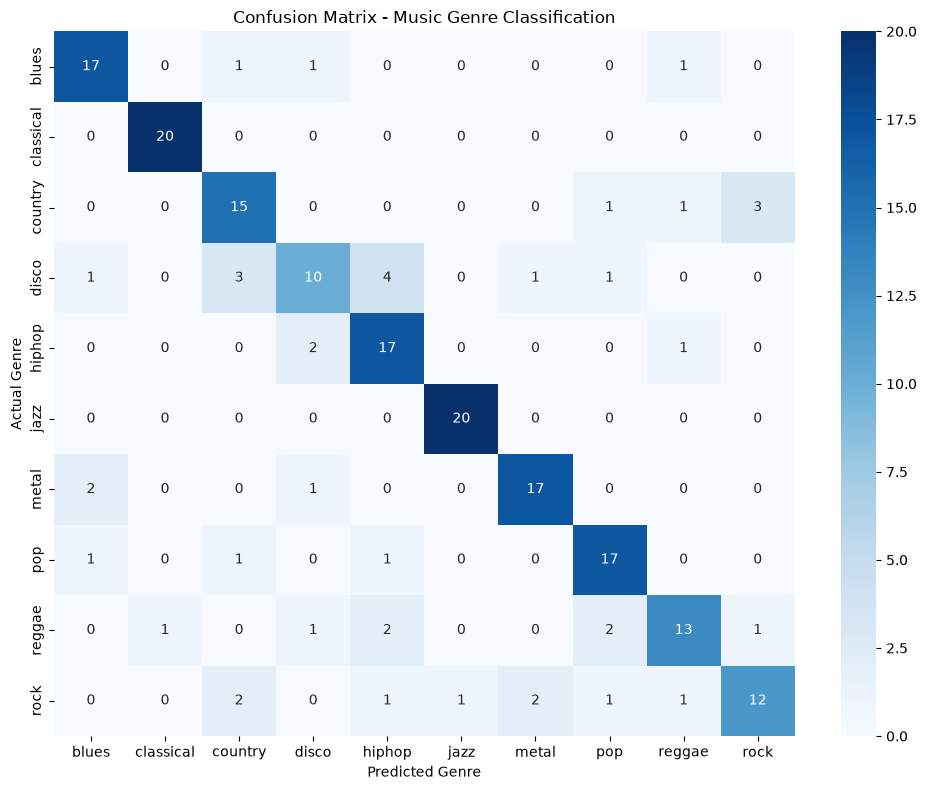

<Figure size 640x480 with 0 Axes>

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Confusion Matrix - Music Genre Classification")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.tight_layout()
plt.show()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")


In [29]:

def extract_features_for_prediction(audio_path):

    audio, sr = librosa.load(audio_path, sr=None)

    # 1. MFCC
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=13
    )

    # 2. Chroma
    chroma = librosa.feature.chroma_stft(
        y=audio, sr=sr
    )

    # 3. Spectral features
    centroid = librosa.feature.spectral_centroid(
        y=audio, sr=sr
    )

    bandwidth = librosa.feature.spectral_bandwidth(
        y=audio, sr=sr
    )

    rolloff = librosa.feature.spectral_rolloff(
        y=audio, sr=sr
    )

    zcr = librosa.feature.zero_crossing_rate(
        y=audio
    )

    # 4. Spectral contrast
    contrast = librosa.feature.spectral_contrast(
        y=audio, sr=sr
    )

    # 5. RMS Energy
    rms = librosa.feature.rms(y=audio)

    # 6. Tempo
    tempo, _ = librosa.beat.beat_track(
        y=audio, sr=sr
    )

    # 7. Tonnetz
    harmonic = librosa.effects.harmonic(audio)

    tonnetz = librosa.feature.tonnetz(
        y=harmonic, sr=sr
    )

    # Combine features in the SAME order as training
    feature_row = np.hstack([
        np.mean(mfcc, axis=1),
        np.std(mfcc, axis=1),

        np.mean(chroma, axis=1),
        np.std(chroma, axis=1),

        np.mean(centroid),
        np.std(centroid),

        np.mean(bandwidth),
        np.std(bandwidth),

        np.mean(rolloff),
        np.std(rolloff),

        np.mean(zcr),
        np.std(zcr),

        np.mean(contrast, axis=1),
        np.std(contrast, axis=1),

        np.mean(rms),
        np.std(rms),

        float(np.mean(tempo)),

        np.mean(tonnetz, axis=1),
        np.std(tonnetz, axis=1)
    ])

    return feature_row.reshape(1, -1)


In [30]:
test_audio = r"C:\Users\LENOVO\OneDrive\Desktop\MusicGenre\archive\Data\genres_original\blues\blues.00006.wav"

test_features = extract_features_for_prediction(test_audio)

print("Extracted feature shape:", test_features.shape)

Extracted feature shape: (1, 87)


In [ ]:
import librosa

gtzan_path = r"C:\Users\LENOVO\OneDrive\Desktop\MusicGenre\archive\Data\genres_original\jazz\jazz.00000.wav"

original_path = r"C:\Users\LENOVO\OneDrive\Desktop\Audio for test\hip hop test.mp3"

for name, path in [("GTZAN", gtzan_path), ("Original Song", original_path)]:
    audio, sr = librosa.load(path, sr=None)

    print(name)
    print("Sample rate:", sr)
    print("Duration:", round(len(audio) / sr, 2), "seconds")
    print("-" * 30)